# House Pricing

<div id='section_1_1'/>

# Часть 1. Изучение файлов с данными и подготовка данных

In [1327]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    RobustScaler,
    FunctionTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_error
from sklearn.decomposition import PCA


sns.set_theme(style="darkgrid")
warnings.simplefilter("ignore")
%matplotlib inline

<div id='section_1_1'/>

## 1.1 Открытие файлов с данными и изучение общей информации

In [1328]:
train_data = pd.read_csv("train.csv")
validation_data = pd.read_csv("test.csv")

In [1329]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [1330]:
train_data = train_data.drop(columns=["Id"])

In [1331]:
X, y = train_data.drop(columns=["SalePrice"]), train_data["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

<Axes: xlabel='SalePrice', ylabel='Count'>

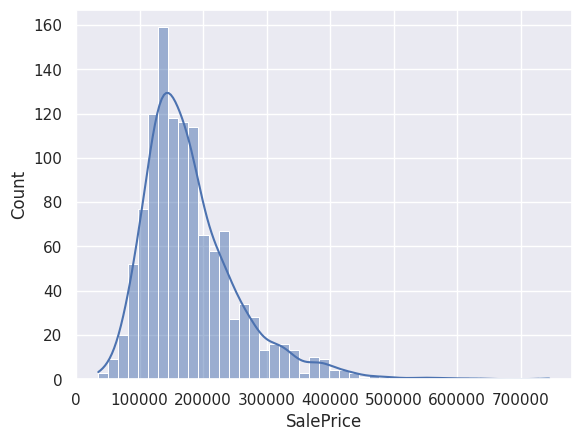

In [1332]:
sns.histplot(y_train, kde=True)

<div id='section_1_2'/>

## 1.2 Предобработка данных

In [1333]:
numeric_data = X_train.select_dtypes([np.number])
numeric_features = numeric_data.columns
cat_features = list(X_train.dtypes[X_train.dtypes == "object"].index)

In [1334]:
num_pipline = Pipeline(steps=[("NumImputer", SimpleImputer(missing_values=np.nan, strategy="mean"))])
cat_pipline = Pipeline(
    steps=[
        ("CatImputer", SimpleImputer(missing_values=np.nan, strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

base_transformer = ColumnTransformer(
    transformers=[("num", num_pipline, numeric_features), ("cat", cat_pipline, cat_features)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
base_transformer.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('num',
                                 Pipeline(steps=[('NumImputer',
                                                  SimpleImputer())]),
                                 Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfB...
                                  'LandContour', 'Utilities', 'LotConfig',
                                  'LandSlope', 'Neighborhood', 'Condition1',
                                  'Condition2', 'BldgType', 'HouseStyle',
                                  'RoofStyle', 'RoofMatl', 'Exterior1st',
                                  'Exterior2nd', 'MasVnrType', 'ExterQual',
                                  'ExterCond', 'Foundation', 'BsmtQual',
                                  'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
                                  'BsmtFinType2', 'Heating', 'HeatingQC',
                                  'CentralAir', 'Electrical', ...])],
                  verbose_feature_names_out=False)

In [1335]:
base_transformer.fit(X_train)
X_train = base_transformer.transform(X_train)
X_test = base_transformer.transform(X_test)

In [1336]:
X_train.columns

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       ...
       'SaleType_ConLw', 'SaleType_New', 'SaleType_Oth', 'SaleType_WD',
       'SaleCondition_Abnorml', 'SaleCondition_AdjLand',
       'SaleCondition_Alloca', 'SaleCondition_Family', 'SaleCondition_Normal',
       'SaleCondition_Partial'],
      dtype='object', length=285)

<div id='section_2'/>

# Часть 2. Анализ данных

In [1337]:
data = pd.concat((X_train, y_train), axis=1)

<Axes: xlabel='YearBuilt'>

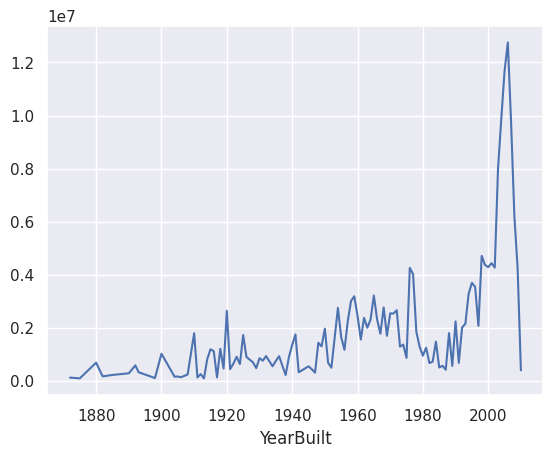

In [1338]:
data.groupby("YearBuilt")["SalePrice"].sum().plot()

In [1339]:
data.groupby("YearBuilt")["SalePrice"].sum().idxmax()

np.float64(2006.0)

In [1340]:
def year_built_trans(data):
    data["BuiltBefore1940"] = (data["YearBuilt"] < 1940).astype("int")
    data["BuiltBetwen1940_1980"] = (data["YearBuilt"].apply(lambda x: 1940 <= x <= 1980)).astype("int")
    data["BuiltBetwen1980_2006"] = (data["YearBuilt"].apply(lambda x: 1980 < x <= 2006)).astype("int")
    data["BuiltAfter2006"] = (data["YearBuilt"].apply(lambda x: 2006 < x)).astype("int")
    return data

In [1341]:
data = year_built_trans(data)

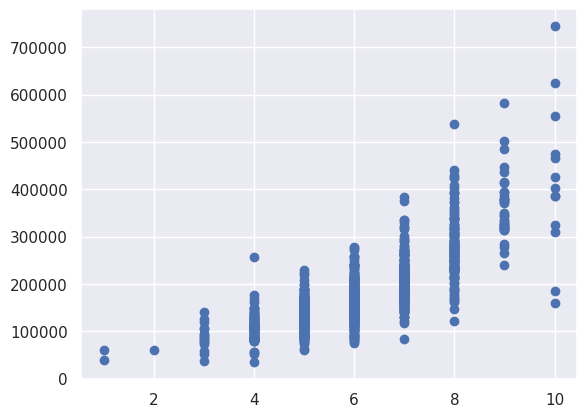

In [1342]:
plt.scatter(data["OverallQual"], y_train)

In [1343]:
def overall_qual_trans(data):
    data["LowQual"] = (data["OverallQual"] < 4).astype("int")
    data["MidQual"] = (data["OverallQual"].apply(lambda x: 4 <= x <= 7)).astype("int")
    data["HighQual"] = (8 <= data["OverallQual"]).astype("int")
    return data

In [1344]:
data = overall_qual_trans(data)

In [1345]:
def other_features_trans(data):
    data["HouseAge"] = data["YrSold"] - data["YearBuilt"]
    data["TotalBathrooms"] = (
        data["FullBath"] + data["HalfBath"] * 0.5 + data["BsmtFullBath"] + data["BsmtHalfBath"] * 0.5
    )
    data["TotalPorchSF"] = data["OpenPorchSF"] + data["EnclosedPorch"] + data["3SsnPorch"] + data["ScreenPorch"]
    data["HasPool"] = (data["PoolArea"] > 0).astype(int)
    data["HasFireplace"] = (data["Fireplaces"] > 0).astype(int)
    data["HasGarage"] = (data["GarageArea"] > 0).astype(int)
    data["TotalSF"] = data["GrLivArea"] + data["TotalBsmtSF"] + data["1stFlrSF"] + data["2ndFlrSF"]
    data.drop(
        columns=[
            "FullBath",
            "HalfBath",
            "BsmtFullBath",
            "BsmtHalfBath",
            "OpenPorchSF",
            "EnclosedPorch",
            "3SsnPorch",
            "ScreenPorch",
            "PoolArea",
            "Fireplaces",
            "GarageArea",
            "GrLivArea",
            "TotalBsmtSF",
            "1stFlrSF",
            "2ndFlrSF",
        ],
        inplace=True,
    )
    return data

In [1346]:
data = other_features_trans(data)

In [1347]:
features_transformer = Pipeline(
    steps=[
        ("year_built", FunctionTransformer(year_built_trans)),
        ("overall_qual", FunctionTransformer(overall_qual_trans)),
        ("other", FunctionTransformer(other_features_trans)),
    ]
)

In [1348]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1168 entries, 254 to 1126
Columns: 285 entries, MSSubClass to TotalSF
dtypes: float64(274), int64(11)
memory usage: 2.5 MB


<Axes: >

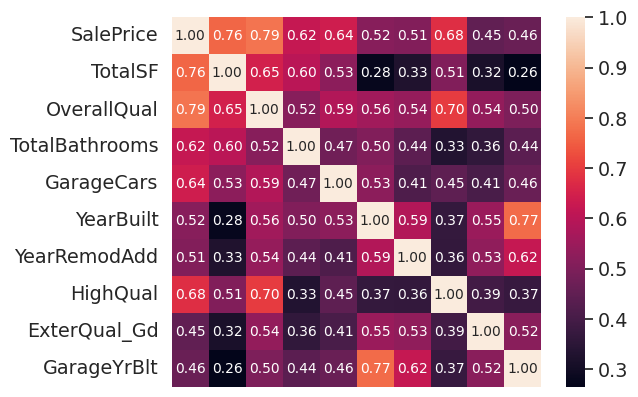

In [1349]:
corrmat = data.corr(method="spearman")
cols = corrmat.nlargest(10, "SalePrice")["SalePrice"].index
cm = np.corrcoef(data[cols].values.T)
sns.set(font_scale=1.25)
sns.heatmap(
    cm,
    cbar=True,
    annot=True,
    square=True,
    fmt=".2f",
    annot_kws={"size": 10},
    xticklabels=False,
    yticklabels=cols.values,
)

<div id='section_2'/>

# Часть 3. Построение модели

In [1359]:
X, y = train_data.drop(columns=["SalePrice"]), train_data["SalePrice"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_train = np.log(y_train)

In [1352]:
linear_params = {"Regressor__Regression__alpha": np.logspace(-2, 4, 20)}

In [1360]:
ridge_pipeline = Pipeline(
    [
        ("base", base_transformer),
        ("features", features_transformer),
        ("scaling", RobustScaler()),
        ("pca", PCA()),
        ("Regression", Ridge()),
    ]
)
lasso_pipeline = Pipeline(
    [
        ("base", base_transformer),
        ("features", features_transformer),
        ("scaling", RobustScaler()),
        ("pca", PCA()),
        ("Regression", Lasso()),
    ]
)

models = [
    {"Regressor": [ridge_pipeline], **linear_params},
    {"Regressor": [lasso_pipeline], **linear_params},
]

In [1384]:
searcher = GridSearchCV(
    Pipeline([("Regressor", LinearRegression())]),
    models,
    cv=10,
    n_jobs=-1,
)
searcher.fit(X_train, y_train)
model = searcher.best_estimator_
model.set_params(**searcher.best_params_)

Pipeline(steps=[('Regressor',
                 Pipeline(steps=[('base',
                                  ColumnTransformer(remainder='passthrough',
                                                    transformers=[('num',
                                                                   Pipeline(steps=[('NumImputer',
                                                                                    SimpleImputer())]),
                                                                   Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF'...
                                  Pipeline(steps=[('year_built',
                                                   FunctionTransformer(func=<function year_built_trans at 0x7b1093dc7ce0>)),
                                                  ('overall_qual',
                                                   FunctionTransformer(func=<function overall_qual_trans at 0x7b10932e71a0>)),
                                                  ('other',
                                                   FunctionTransformer(func=<function other_features_trans at 0x7b10932e79c0>))])),
                                 ('scaling', RobustScaler()), ('pca', PCA()),
                                 ('Regression',
                                  Ridge(alpha=np.float64(61.584821106602604)))]))])

In [1385]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("RMSE = %.4f" % root_mean_squared_error(y_test, np.exp(y_pred)))

RMSE = 27326.9506


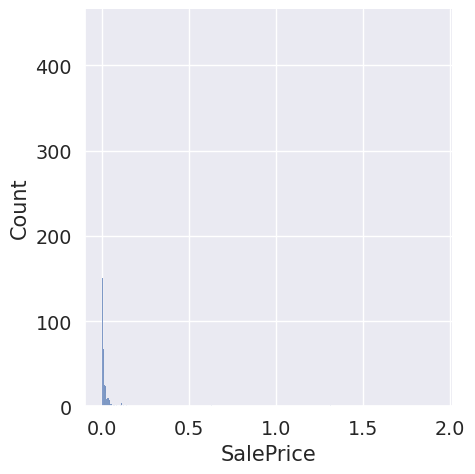

In [1386]:
error = (y_train - model.predict(X_train)) ** 2
sns.displot(error)

In [1387]:
mask = error < np.quantile(error, 0.95)

In [1388]:
model.fit(X_train[mask], y_train[mask])
y_pred = model.predict(X_test)
print("RMSE = %.4f" % root_mean_squared_error(y_test, np.exp(y_pred)))

RMSE = 23450.4883


In [1380]:
final_pred = np.exp(model.predict(validation_data))

In [1381]:
submission = pd.read_csv("sample_submission.csv", index_col="Id")

In [1382]:
submission["SalePrice"] = final_pred

In [1383]:
submission

,SalePrice
Id,
1461,112051.479163
1462,142991.146957
1463,181484.935536
1464,198912.233242
1465,187824.362776
...,...
2915,90427.684793
2916,92248.893624
2917,175671.781002


In [1374]:
submission.to_csv("/content/new_submission.csv")

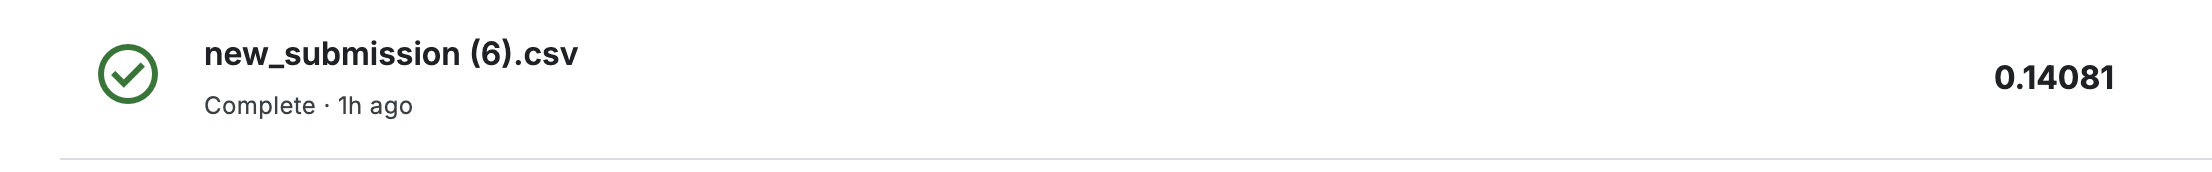